# 06 · Baseline Models

**The questions:**
1. How well do standard machine-learning models detect the 10 classes?
2. Do the two engineered features (`fe_total_bytes`, `fe_byte_balance`) help?

| | |
|---|---|
| **Input** | The two feature sets from Notebook 05 (`original42`, `total_and_byte44`), for the `train` and `model_selection` roles |
| **What we do** | Train 3 models on each set with identical settings, score them on `model_selection`, study the mistakes |
| **Output** | 6 trained models, their predictions and scores, and a provisional best baseline |

### Why baselines?

The project's main goal is a deep-learning detector (as in the reference paper). A complex model is only worth it if it **beats simple, strong models**.
The baselines set the bar that every later model must clear.

| Model | In one sentence | Input version |
|---|---|---|
| **Logistic regression** | Draws straight-line boundaries between classes; simple and fast | scaled |
| **Decision tree** | Asks a sequence of yes/no questions ("is sttl > 100?") | tree |
| **LightGBM** | Builds 120 small trees, each one correcting the mistakes of the previous ones | tree |

**Rules (from Notebook 02):** fit on `train` only; compare on `model_selection`; `calibration` stays untouched; the test file is not used.

## 1. Setup and load the inputs

In [1]:
import sys
import time
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_recall_fscore_support)
from sklearn.multiclass import OneVsRestClassifier
from sklearn.tree import DecisionTreeClassifier

import warnings
warnings.filterwarnings('ignore', message='X does not have valid feature names')   # harmless LightGBM/sklearn naming notice

from src.notebook_helpers import (ROOT, TRAIN_CSV, RAW_SHA256, CLASSES, DATA, MODELS,
                                  sha256, save_table, save_figure, save_json, read_json, setup_style, write_leaderboard)
setup_style()
assert sha256(TRAIN_CSV) == RAW_SHA256['train']

SETS = ['original42', 'total_and_byte44']
NORMAL = CLASSES.index('Normal')
X = {(s, v, r): sparse.load_npz(DATA / f'05_{s}_{v}_{r}.npz')
     for s in SETS for v in ['tree', 'scaled'] for r in ['train', 'model_selection']}
targets = {r: pd.read_csv(DATA / f'03_targets_{r}.csv') for r in ['train', 'model_selection']}
y_train = pd.Categorical(targets['train'].attack_cat, categories=CLASSES).codes
y_eval = pd.Categorical(targets['model_selection'].attack_cat, categories=CLASSES).codes
assert (y_train >= 0).all() and (y_eval >= 0).all()

print('train rows:', len(y_train), '| model_selection rows:', len(y_eval))
display(pd.Series(np.bincount(y_eval, minlength=10), index=CLASSES, name='model_selection rows per class').to_frame().T)

train rows: 140273 | model_selection rows: 17534


,Analysis,Backdoor,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Shellcode,Worms
model_selection rows per class,200,175,1226,3340,1818,4000,5600,1049,113,13


Note the bottom of that table: only **13 Worms rows** and 113 Shellcode rows. On rare classes, one or two rows can swing a score.

## 2. The models and their settings

The settings below were chosen **in advance**, using a small search with grouped folds inside the `train` rows only
(earlier project version, recorded in `models/revision_v2/06_frozen_family_settings.json`). We use the **same settings for both feature sets**,
so any difference in score comes from the features, not from tuning. We do **not** tune on `model_selection`.

In [2]:
frozen = read_json(ROOT / 'models/revision_v2/06_frozen_family_settings.json')['chosen']
print('frozen choices:', frozen)


def make_model(name):
    if name == 'logistic':
        return OneVsRestClassifier(LogisticRegression(solver='liblinear', C=frozen['logistic']['C'], max_iter=500, random_state=42), n_jobs=1)
    if name == 'decision_tree':
        return DecisionTreeClassifier(max_depth=frozen['decision_tree']['max_depth'],
                                      min_samples_leaf=frozen['decision_tree']['min_samples_leaf'], random_state=42)
    if name == 'lightgbm':
        return LGBMClassifier(objective='multiclass', n_estimators=120, learning_rate=0.1, num_leaves=frozen['lightgbm']['num_leaves'],
                              reg_lambda=1.0, min_child_samples=20, random_state=42, n_jobs=2, deterministic=True,
                              force_col_wise=True, verbosity=-1)


MODELS_TO_RUN = {'logistic': 'scaled', 'decision_tree': 'tree', 'lightgbm': 'tree'}

frozen choices: {'logistic': {'C': 1.0}, 'decision_tree': {'max_depth': 24, 'min_samples_leaf': 2}, 'lightgbm': {'num_leaves': 31}}


**A note on `reg_lambda=1.0` for LightGBM.** This is a small penalty that stops the value in any tree leaf from becoming too large.
The library's own default is 0. While rebuilding this notebook we found that without the penalty LightGBM becomes **unstable on this data**:
its macro F1 falls from about 0.55 after 60 trees to about 0.46 after 120 trees, instead of rising to about 0.63.
The frozen settings always included `reg_lambda=1.0`, so we state it explicitly here.

## 3. How we score a model

One function computes every number we agreed on in Notebook 02. Turning 10-class predictions into Attack/Normal is simple:
anything not predicted as Normal counts as "Attack". The **attack score** for the precision-recall curve is `1 - P(Normal)`.

In [3]:
def score(y_true, proba):
    pred = proba.argmax(axis=1)
    attack_true, attack_pred = y_true != NORMAL, pred != NORMAL
    tn = int((~attack_true & ~attack_pred).sum()); fp = int((~attack_true & attack_pred).sum())
    fn = int((attack_true & ~attack_pred).sum()); tp = int((attack_true & attack_pred).sum())
    worms = CLASSES.index('Worms')
    return {'macro F1': f1_score(y_true, pred, average='macro', labels=range(10), zero_division=0),
            'accuracy': accuracy_score(y_true, pred),
            'weighted F1': f1_score(y_true, pred, average='weighted', labels=range(10), zero_division=0),
            'attack recall': tp / (tp + fn),
            'attack precision': tp / (tp + fp),
            'false-positive rate': fp / (fp + tn),
            'attack avg precision': average_precision_score(attack_true, 1 - proba[:, NORMAL]),
            'Worms correct (of 13)': int(((y_true == worms) & (pred == worms)).sum())}

## 4. Train the six models

In [4]:
fitted, probabilities, rows = {}, {}, []
for model_name, version in MODELS_TO_RUN.items():
    for set_name in SETS:
        model = make_model(model_name)
        start = time.time()
        model.fit(X[(set_name, version, 'train')], y_train)
        seconds = time.time() - start
        proba = model.predict_proba(X[(set_name, version, 'model_selection')])
        fitted[(model_name, set_name)], probabilities[(model_name, set_name)] = model, proba
        rows.append({'model': model_name, 'feature set': set_name, 'fit seconds': round(seconds, 1), **score(y_eval, proba)})
        print(f'{model_name:14s} {set_name:17s} macro F1 = {rows[-1]["macro F1"]:.4f}  ({seconds:.0f} s)')

results = pd.DataFrame(rows)
save_table(results, '06_results')

logistic       original42        macro F1 = 0.4169  (33 s)


logistic       total_and_byte44  macro F1 = 0.4242  (38 s)


decision_tree  original42        macro F1 = 0.6097  (12 s)


decision_tree  total_and_byte44  macro F1 = 0.6160  (13 s)


lightgbm       original42        macro F1 = 0.6307  (14 s)


lightgbm       total_and_byte44  macro F1 = 0.6320  (14 s)


WindowsPath('D:/projects/Botnet attack detection/results/tables/v3/06_results.csv')

### Why one run per model, when the neural networks get three seeds?

A random seed only matters if the model uses randomness. Our **LightGBM** settings use every row and every feature in every tree
(no row or column sampling), and our **logistic regression** solver is deterministic, so a different seed should give **exactly** the same model.
The **decision tree** uses the seed to break ties between equally good splits, which can change the whole tree below that point.

We check this directly: LightGBM is retrained once with seed 43; the decision tree is retrained with seeds 43 and 44 on both feature sets.

In [5]:
other = make_model('lightgbm').set_params(random_state=43)
other.fit(X[('total_and_byte44', 'tree', 'train')], y_train)
lgbm_changed = int((other.predict_proba(X[('total_and_byte44', 'tree', 'model_selection')]).argmax(1)
                    != probabilities[('lightgbm', 'total_and_byte44')].argmax(1)).sum())
print(f'LightGBM, seed 43 instead of 42: {lgbm_changed} of {len(y_eval):,} predictions change')

tree_seeds = []
for set_name in SETS:
    for seed in [42, 43, 44]:
        if seed == 42:
            proba = probabilities[('decision_tree', set_name)]
        else:
            tree = make_model('decision_tree').set_params(random_state=seed).fit(X[(set_name, 'tree', 'train')], y_train)
            proba = tree.predict_proba(X[(set_name, 'tree', 'model_selection')])
        tree_seeds.append({'feature set': set_name, 'seed': seed, **score(y_eval, proba)})
tree_seeds = pd.DataFrame(tree_seeds)
save_table(tree_seeds, '06_decision_tree_seeds')
display(tree_seeds[['feature set', 'seed', 'macro F1', 'accuracy', 'Worms correct (of 13)']])
display(tree_seeds.groupby('feature set')['macro F1'].agg(['mean', 'std', 'min', 'max']).rename(columns=lambda c: f'macro F1 {c}'))

LightGBM, seed 43 instead of 42: 0 of 17,534 predictions change


,feature set,seed,macro F1,accuracy,Worms correct (of 13)
0,original42,42,0.6097,0.8146,6
1,original42,43,0.6134,0.8154,7
2,original42,44,0.6120,0.8158,6
3,total_and_byte44,42,0.6160,0.8136,8
4,total_and_byte44,43,0.6045,0.8142,6
5,total_and_byte44,44,0.6114,0.8137,7


,macro F1 mean,macro F1 std,macro F1 min,macro F1 max
feature set,,,,
original42,0.6117,0.0019,0.6097,0.6134
total_and_byte44,0.6107,0.0058,0.6045,0.6160


**What we see:**

- **LightGBM gives exactly the same predictions with another seed**, so a single run fully describes it.
- **The decision tree moves noticeably between seeds** (by about 0.01 macro F1). That is **larger than its engineered-feature gain** in section 6 (0.006).
  Averaged over the three seeds, the two feature sets score **almost the same: 0.612 (original42) vs 0.611 (total_and_byte44)**.
  So the tree's seed-42 "gain" from the engineered features is not real. For the decision tree we report the **3-seed mean** in the final results table.

## 5. Results

fit seconds  macro F1  accuracy  weighted F1  attack recall  attack precision  false-positive rate  attack avg precision  Worms correct (of 13)
model         feature set                                                                                                                                                      
logistic      original42            33.3000    0.4169    0.7744       0.7580         0.9734            0.9366               0.1404                0.9920                      0
              total_and_byte44      38.5000    0.4242    0.7768       0.7605         0.9718            0.9382               0.1364                0.9923                      0
decision_tree original42            11.8000    0.6097    0.8146       0.8138         0.9635            0.9591               0.0875                0.9742                      6
              total_and_byte44      12.8000    0.6160    0.8136       0.8126         0.9623            0.9603               0.0848                0.9733                      8
lightgbm      original42            14.1000    0.6307    0.8366       0.8147         0.9760            0.9609               0.0846                0.9968                      8
              total_and_byte44      14.2000    0.6320    0.8356       0.8137         0.9753            0.9609               0.0845                0.9967                      9

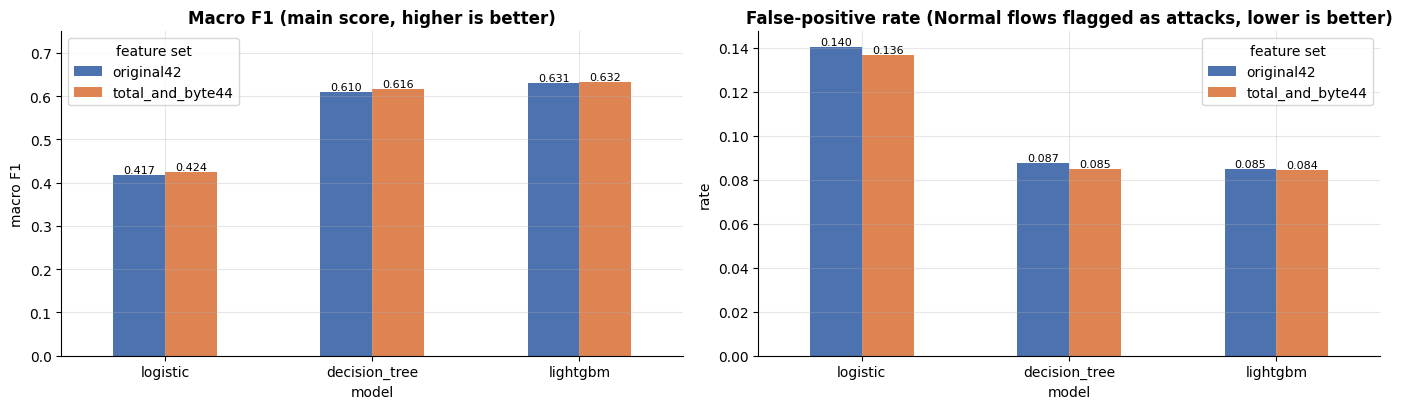

In [6]:
display(results.set_index(['model', 'feature set']))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
pivot = results.pivot(index='model', columns='feature set', values='macro F1').loc[list(MODELS_TO_RUN)]
pivot.plot.bar(ax=axes[0], rot=0, color=['#4C72B0', '#DD8452'])
axes[0].set(title='Macro F1 (main score, higher is better)', ylim=(0, 0.75), ylabel='macro F1')
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='%.3f', fontsize=8)
pivot = results.pivot(index='model', columns='feature set', values='false-positive rate').loc[list(MODELS_TO_RUN)]
pivot.plot.bar(ax=axes[1], rot=0, color=['#4C72B0', '#DD8452'])
axes[1].set(title='False-positive rate (Normal flows flagged as attacks, lower is better)', ylabel='rate')
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.3f', fontsize=8)
plt.tight_layout(); save_figure(fig, '06_model_comparison'); plt.show()

**What we see (answer to question 1):**

- **LightGBM is the strongest** model (macro F1 about 0.63), the decision tree is close behind (about 0.61), and logistic regression is far behind (about 0.42).
  Straight-line boundaries are not enough for this data.
- **Accuracy is much higher than macro F1** (about 0.84 vs 0.63 for LightGBM). Accuracy is dominated by the big classes; macro F1 shows that
  several classes are still handled poorly.
- All models **catch about 96-98% of attacks**. The difference is in false alarms: logistic regression flags about 14% of Normal flows, the tree models about 8-9%.

## 6. Do the engineered features help?

We compare the two sets **within each model**. Because `model_selection` has few rows for some classes, we also estimate how uncertain the
difference is with a **bootstrap**: we resample the 17,534 rows 1,000 times (with replacement), recompute the macro F1 difference each time,
and look at the middle 95% of those differences. If that interval includes 0, the difference could easily be luck.

In [7]:
rng = np.random.default_rng(0)
boot_idx = rng.integers(0, len(y_eval), size=(1000, len(y_eval)), dtype=np.int32)

diffs = []
for model_name in MODELS_TO_RUN:
    base = probabilities[(model_name, 'original42')].argmax(axis=1)
    new = probabilities[(model_name, 'total_and_byte44')].argmax(axis=1)
    observed = f1_score(y_eval, new, average='macro', labels=range(10)) - f1_score(y_eval, base, average='macro', labels=range(10))
    boot = [f1_score(y_eval[i], new[i], average='macro', labels=range(10), zero_division=0)
            - f1_score(y_eval[i], base[i], average='macro', labels=range(10), zero_division=0) for i in boot_idx]
    low, high = np.percentile(boot, [2.5, 97.5])
    diffs.append({'model': model_name, 'macro F1 original42': f1_score(y_eval, base, average='macro', labels=range(10)),
                  'macro F1 total_and_byte44': f1_score(y_eval, new, average='macro', labels=range(10)),
                  'difference': observed, '95% interval low': low, '95% interval high': high,
                  'clear improvement?': 'yes' if low > 0 else 'no - could be chance'})
diffs = pd.DataFrame(diffs)
save_table(diffs, '06_engineered_feature_effect')
display(diffs)

,model,macro F1 original42,macro F1 total_and_byte44,difference,95% interval low,95% interval high,clear improvement?
0,logistic,0.4169,0.4242,0.0073,0.0025,0.0131,yes
1,decision_tree,0.6097,0.6160,0.0064,-0.0121,0.0296,no - could be chance
2,lightgbm,0.6307,0.6320,0.0012,-0.0123,0.0158,no - could be chance


Where does the difference come from? Per-class F1 for each model, and the change:

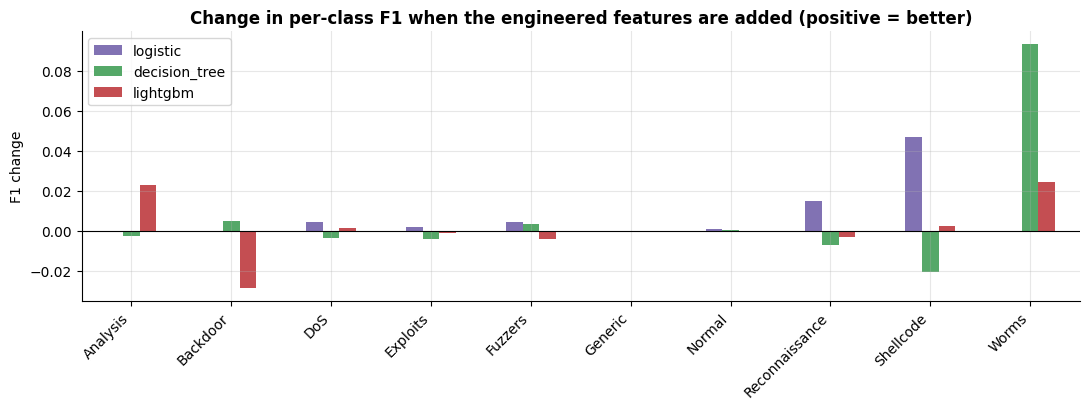

In [8]:
def per_class_f1(model_name, set_name):
    pred = probabilities[(model_name, set_name)].argmax(axis=1)
    return pd.Series(f1_score(y_eval, pred, average=None, labels=range(10), zero_division=0), index=CLASSES)

class_change = pd.DataFrame({m: per_class_f1(m, 'total_and_byte44') - per_class_f1(m, 'original42') for m in MODELS_TO_RUN})
save_table(class_change, '06_per_class_f1_change', index=True)

fig, ax = plt.subplots(figsize=(11, 4.2))
class_change.plot.bar(ax=ax, color=['#8172B3', '#55A868', '#C44E52'])
ax.axhline(0, color='black', lw=0.8)
ax.set(title='Change in per-class F1 when the engineered features are added (positive = better)', ylabel='F1 change')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); save_figure(fig, '06_per_class_change'); plt.show()

**What we see (answer to question 2):**

- All three models score slightly higher with the engineered features (by about 0.001 to 0.007 macro F1).
- For **logistic regression** the gain is small but clear (the interval stays above 0). A linear model cannot build "total" or "balance"
  from separate columns by itself, so handing them over helps.
- For the two strong models, **decision tree and LightGBM**, the interval includes 0: the gain **could easily be chance**. For the decision tree
  the gain is also smaller than the change caused by simply using another seed, and it disappears in the 3-seed average (section 4). Trees can already
  combine `sbytes` and `dbytes` through their splits.
- The per-class changes go both ways. For the tree models a large part of the change comes from **Worms**, where one extra correct row out of 13
  moves the Worms F1 a lot.

**Honest conclusion:** the engineered features **help the simple linear model** and are **neutral to slightly positive for the tree models**.
They stay in the selected set because they cost almost nothing, but the original 42 remain the reference.

## 7. A closer look at the best model

LightGBM with `total_and_byte44` has the highest macro F1. Here is what it gets right and wrong, class by class.

In [9]:
BEST = ('lightgbm', 'total_and_byte44')
best_pred = probabilities[BEST].argmax(axis=1)
precision, recall, f1, support = precision_recall_fscore_support(y_eval, best_pred, labels=range(10), zero_division=0)
report = pd.DataFrame({'precision': precision, 'recall': recall, 'F1': f1, 'rows': support,
                       'correct': [int(((y_eval == k) & (best_pred == k)).sum()) for k in range(10)]}, index=CLASSES)
save_table(report, '06_best_model_per_class', index=True)
display(report.sort_values('F1'))

,precision,recall,F1,rows,correct
DoS,0.6667,0.0701,0.1269,1226,86
Backdoor,0.5417,0.1486,0.2332,175,26
Analysis,0.5660,0.1500,0.2372,200,30
Worms,0.7500,0.6923,0.7200,13,9
Shellcode,0.7154,0.7788,0.7458,113,88
Exploits,0.6225,0.9557,0.7539,3340,3192
Fuzzers,0.7511,0.7651,0.7580,1818,1391
Reconnaissance,0.9263,0.7426,0.8243,1049,779
Normal,0.9456,0.9155,0.9303,5600,5127
Generic,0.9992,0.9808,0.9899,4000,3923


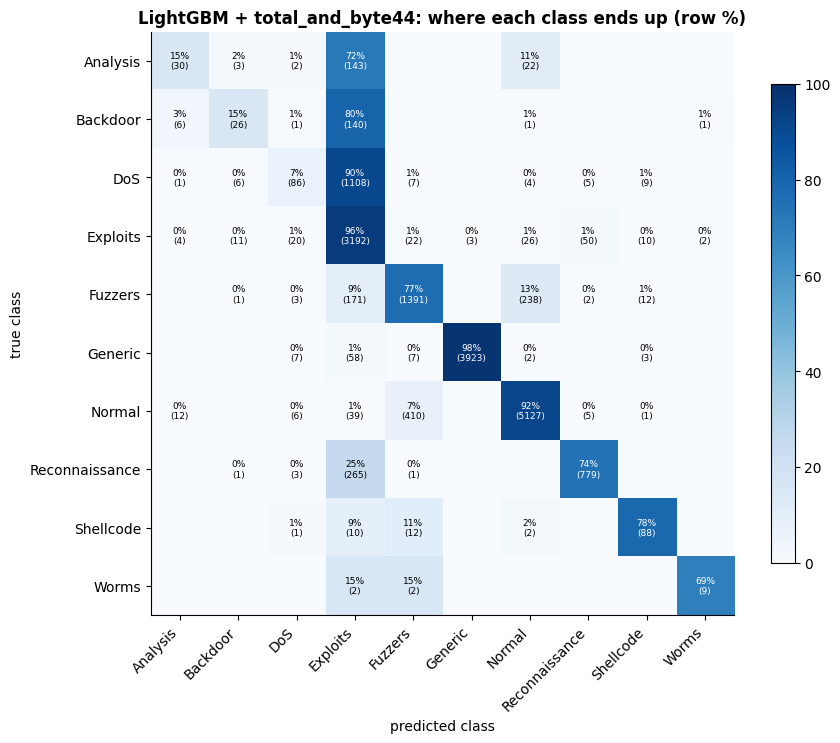

In [10]:
cm = confusion_matrix(y_eval, best_pred, labels=range(10))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
save_table(pd.DataFrame(cm, index=CLASSES, columns=CLASSES), '06_best_model_confusion_counts', index=True)

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(10), CLASSES, rotation=45, ha='right'); ax.set_yticks(range(10), CLASSES); ax.grid(False)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, f'{cm_pct[i, j]:.0f}%\n({cm[i, j]})', ha='center', va='center', fontsize=6.5,
                    color='white' if cm_pct[i, j] > 60 else 'black')
ax.set(xlabel='predicted class', ylabel='true class', title='LightGBM + total_and_byte44: where each class ends up (row %)')
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); save_figure(fig, '06_best_model_confusion'); plt.show()

**What we see:**

- **Generic and Normal** are recognised very well (F1 0.99 and 0.93). Exploits, Fuzzers, Reconnaissance, Shellcode and Worms reach F1 0.72-0.82.
- **Analysis, Backdoor and DoS are mostly predicted as Exploits**: 143 of 200 Analysis rows, 140 of 175 Backdoor rows and 1,108 of 1,226 DoS rows.
- The main Normal-side mistake is **Normal vs Fuzzers** (410 Normal rows predicted as Fuzzers, 238 Fuzzers rows predicted as Normal).
- **Worms**: 9 of 13 correct; the other 4 went to Exploits and Fuzzers.

This is exactly what Notebooks 02 and 03 predicted: these classes share identical or near-identical measurements.

## 8. Why are Analysis, Backdoor and DoS so hard?

Notebook 02 found that many patterns carry **several different labels** in the training file. We check whether the model's mistakes
happen mostly on rows whose pattern has such conflicting labels.

In [11]:
roles = pd.read_csv(DATA / '02_roles.csv')
labels_per_pattern = roles.groupby('pattern').attack_cat.nunique()
eval_rows = roles[roles.role == 'model_selection'].copy()
eval_rows['conflicting pattern'] = eval_rows.pattern.map(labels_per_pattern).gt(1).to_numpy()
eval_rows['correct'] = best_pred == y_eval

hard = ['Analysis', 'Backdoor', 'DoS', 'Exploits']
error_table = (eval_rows[eval_rows.attack_cat.isin(hard)]
               .groupby(['attack_cat', 'conflicting pattern']).correct.agg(['size', 'mean'])
               .rename(columns={'size': 'rows', 'mean': 'share correct'}))
save_table(error_table, '06_errors_and_conflicts', index=True)
display(error_table)

overall = eval_rows.groupby('conflicting pattern').correct.agg(['size', 'mean']).rename(columns={'size': 'rows', 'mean': 'share correct'})
display(overall)

rows  share correct
attack_cat conflicting pattern                     
Analysis   False                  54         0.4259
           True                  146         0.0479
Backdoor   False                  42         0.5476
           True                  133         0.0226
DoS        False                 250         0.3320
           True                  976         0.0031
Exploits   False                2004         0.9341
           True                 1336         0.9880

,rows,share correct
conflicting pattern,,
False,14456,0.9164
True,3078,0.4558


**What we see:** For these classes, rows whose pattern has **conflicting labels** are predicted correctly far less often than rows with a clean pattern.
On identical measurements the model can only pick the most common label (usually Exploits), so the minority labels are always "wrong".
A large part of the remaining error is **built into the labels**, not a weakness that a bigger model can easily fix.

## 9. Attack vs Normal: precision-recall curves

For a security team the first question is "is this an attack at all?". The curve shows the trade-off between catching attacks (recall)
and not raising false alarms (precision) as we move the alarm threshold on the attack score `1 - P(Normal)`.

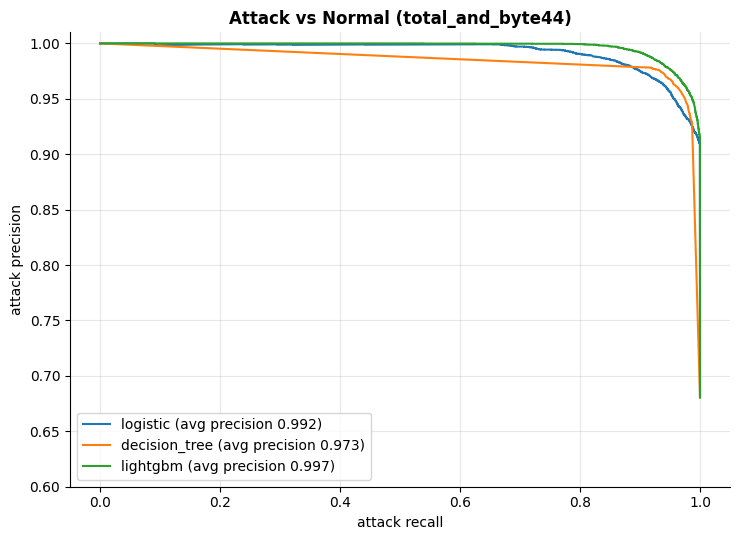

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
attack_true = y_eval != NORMAL
for (model_name, set_name), proba in probabilities.items():
    if set_name != 'total_and_byte44':
        continue
    p, r, _ = precision_recall_curve(attack_true, 1 - proba[:, NORMAL])
    ap = average_precision_score(attack_true, 1 - proba[:, NORMAL])
    ax.plot(r, p, label=f'{model_name} (avg precision {ap:.3f})')
ax.set(xlabel='attack recall', ylabel='attack precision', ylim=(0.6, 1.01), title='Attack vs Normal (total_and_byte44)')
ax.legend(); plt.tight_layout(); save_figure(fig, '06_attack_precision_recall'); plt.show()

**What we see:** Separating attacks from normal traffic is the easy part. LightGBM keeps precision near 1 until very high recall (average precision 0.997),
and even logistic regression reaches 0.99. The single decision tree is lowest (0.97) because its probabilities are coarse (few distinct values).
The difficulty of this dataset lies in telling **attack types** apart, not in spotting attacks.

## 10. What does LightGBM rely on?

**Feature importance (gain)** measures how much each feature improved the trees' decisions in total. One-hot columns of the same text feature are added together.

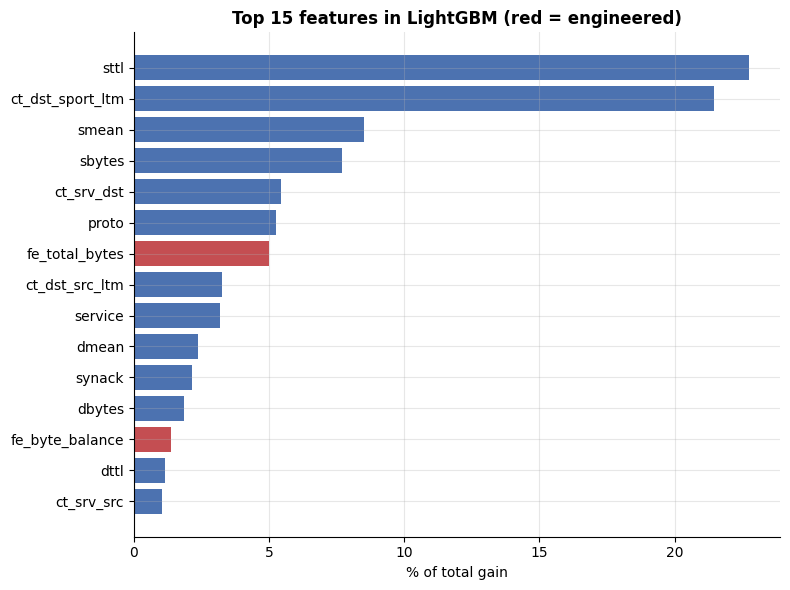

Rank of engineered features: {'fe_total_bytes': 7, 'fe_byte_balance': 13}


In [13]:
columns = read_json(MODELS / '05_feature_sets.json')['columns']['total_and_byte44/tree']
gain = pd.Series(fitted[BEST].booster_.feature_importance('gain'), index=columns)
source = gain.index.str.replace(r'^(num__|engineered__)', '', regex=True)
source = np.where(gain.index.str.startswith('cat__'), gain.index.str.split('__').str[1].str.split('_').str[0], source)
importance = gain.groupby(source).sum().sort_values(ascending=False)
importance = importance / importance.sum() * 100
save_table(importance.rename('% of total gain').to_frame(), '06_lightgbm_importance', index=True)

fig, ax = plt.subplots(figsize=(8, 6))
top = importance.head(15)[::-1]
ax.barh(top.index, top.values, color=['#C44E52' if n.startswith('fe_') else '#4C72B0' for n in top.index])
ax.set(xlabel='% of total gain', title='Top 15 features in LightGBM (red = engineered)')
plt.tight_layout(); save_figure(fig, '06_lightgbm_importance'); plt.show()
print('Rank of engineered features:', {f: int(np.flatnonzero(importance.index == f)[0]) + 1 for f in ['fe_total_bytes', 'fe_byte_balance']})

**What we see:** The model leans heavily on two features: `sttl` (TTL, 23% of the gain) and `ct_dst_sport_ltm` (a "recent flows" counter, 21%),
then packet size and bytes. `sttl` being the top feature is a reminder from Notebook 03: it may be a fingerprint of this testbed.
The engineered features are used (`fe_total_bytes` ranks 7th, `fe_byte_balance` 13th) but do not dominate, which matches the small effect in section 6.

## 11. Provisional decision

**Rule (fixed in advance):** choose the model and feature set with the highest macro F1 on `model_selection`. If two are within 0.001,
prefer the simpler one (fewer features).

In [14]:
ranked = results.sort_values('macro F1', ascending=False).reset_index(drop=True)
best_row, runner_up = ranked.iloc[0], ranked.iloc[1]
gap = best_row['macro F1'] - runner_up['macro F1']
if gap < 0.001 and runner_up['feature set'] == 'original42':
    best_row = runner_up
choice = {'model': best_row['model'], 'feature set': best_row['feature set'], 'macro F1': round(float(best_row['macro F1']), 4),
          'runner-up': f"{runner_up['model']} / {runner_up['feature set']} ({runner_up['macro F1']:.4f})",
          'status': 'provisional development choice; final test performance unknown'}
save_json(choice, MODELS / '06_provisional_choice.json')
display(pd.Series(choice).to_frame('decision'))

,decision
model,lightgbm
feature set,total_and_byte44
macro F1,0.6320
runner-up,lightgbm / original42 (0.6307)
status,provisional development choice; final test per...


**Decision:** **LightGBM with `total_and_byte44`** is the provisional best baseline (macro F1 about 0.632). LightGBM with `original42`
is a very close second (about 0.631), and the difference is within chance (section 6).

Two warnings:

- This score is **slightly optimistic**: we picked the best of six candidates on the same `model_selection` rows we report it on.
- It is **not a final result**. The official test file has not been touched, and its class mix is different (Notebook 01).

## 12. Checks and save

The predictions must match those of the earlier project version exactly, since the inputs and settings are identical.
Then we save the models, predictions and scores.

In [15]:
check = []
for (model_name, set_name), proba in probabilities.items():
    old = pd.read_csv(ROOT / f'data/processed/revision_v2/06_{model_name}_{set_name}_predictions.csv')
    old_pred = pd.Categorical(old.predicted_attack_cat, categories=CLASSES).codes
    check.append({'model': model_name, 'feature set': set_name, 'same predictions as earlier version': bool((old_pred == proba.argmax(axis=1)).all())})
check = pd.DataFrame(check)
display(check)
assert check.iloc[:, -1].all()

for (model_name, set_name), model in fitted.items():
    joblib.dump(model, MODELS / f'06_{model_name}_{set_name}.joblib')
    out = targets['model_selection'][['row_position', 'id', 'attack_cat']].copy()
    out['predicted'] = np.asarray(CLASSES)[probabilities[(model_name, set_name)].argmax(axis=1)]
    out['attack_score'] = 1 - probabilities[(model_name, set_name)][:, NORMAL]
    for k, c in enumerate(CLASSES):
        out[f'p_{c}'] = probabilities[(model_name, set_name)][:, k]
    out.to_csv(DATA / f'06_{model_name}_{set_name}_predictions.csv', index=False)
leaderboard = []
for _, r in results.iterrows():
    row = {'model': {'logistic': 'Logistic regression', 'decision_tree': 'Decision tree', 'lightgbm': 'LightGBM'}[r['model']],
           'feature set': r['feature set'], 'runs': 1, 'macro F1 mean': r['macro F1'], 'macro F1 std': np.nan,
           'accuracy': r['accuracy'], 'attack recall': r['attack recall'], 'false-positive rate': r['false-positive rate'],
           'attack avg precision': r['attack avg precision'], 'Worms correct (of 13)': r['Worms correct (of 13)'],
           'train minutes per run': r['fit seconds'] / 60}
    if r['model'] == 'decision_tree':          # seed-sensitive: report the 3-seed mean and spread
        part = tree_seeds[tree_seeds['feature set'] == r['feature set']]
        row.update({'runs': 3, 'macro F1 mean': part['macro F1'].mean(), 'macro F1 std': part['macro F1'].std(),
                    'accuracy': part['accuracy'].mean(), 'attack recall': part['attack recall'].mean(),
                    'false-positive rate': part['false-positive rate'].mean(), 'attack avg precision': part['attack avg precision'].mean(),
                    'Worms correct (of 13)': part['Worms correct (of 13)'].mean()})
    leaderboard.append(row)
write_leaderboard('06', leaderboard)
assert sha256(TRAIN_CSV) == RAW_SHA256['train']
print('Saved 6 models, their predictions and the leaderboard rows. Calibration rows and the test file were not used.')

,model,feature set,same predictions as earlier version
0,logistic,original42,True
1,logistic,total_and_byte44,True
2,decision_tree,original42,True
3,decision_tree,total_and_byte44,True
4,lightgbm,original42,True
5,lightgbm,total_and_byte44,True


Saved 6 models, their predictions and the leaderboard rows. Calibration rows and the test file were not used.


## Summary

### What we learned

| Question | Answer |
|---|---|
| Best baseline | **LightGBM** (macro F1 about 0.63); decision tree about 0.61; logistic regression about 0.42 |
| Attack vs Normal | Easy for tree models: LightGBM catches about 97.5% of attacks with about 8.5% false alarms (attack average precision 0.997) |
| Hard classes | Analysis, Backdoor and DoS are mostly predicted as Exploits, largely because their measurements are identical (label conflicts) |
| Rare classes | Worms is partly recognised (9 of 13 with the best model), but 13 rows are too few for firm conclusions |
| Engineered features | Clear small gain for logistic regression; for the tree models the gain is within chance (for the decision tree it is smaller than its seed-to-seed variation). Kept as cheap extras; original42 stays the reference |
| Reproducibility | LightGBM gives identical results with any seed; the decision tree varies by about 0.01 between seeds, so it is reported as a 3-seed mean |
| Provisional choice | **LightGBM + total_and_byte44**, macro F1 about 0.632 (slightly optimistic, not a final test result) |

### What is still uncertain

- Performance on the official test file is unknown.
- Whether the small engineered-feature gain is real.
- How much of the remaining error any model can remove, given the label conflicts.

### What comes next

**Notebook 07** (already in the project) trains a **neural network reference model (MLP)** on the same two feature sets and compares it with these
LightGBM baselines. Later notebooks will test the deep-learning architecture, calibrate confidence on the `calibration` rows, and finally
evaluate once on the official test file.